# Catching Credit Card Fraud with Naïve Bayes
### A classifier built from scratch, using nothing more than counting and Bayes' theorem

---

**The question this notebook answers:** a bank sees a new credit card transaction. Should it be flagged as possible fraud?

**The approach:** look at 20,000 past transactions where we already know the answer, learn what fraud *typically* looks like and what a normal purchase *typically* looks like, then ask of each new transaction: *which of the two does this resemble more?*

| Section | What happens |
|---|---|
| 1 | The big idea: Bayes' theorem |
| 2 | Small math tools |
| 3 | A tiny example we can check with a calculator |
| 4 | Loading the real data |
| 5 | Building and training the classifier |
| 6 | What the classifier learned |
| 7 | How well does it work? |
| 8 | Looking inside one decision |
| 9 | Limitations and next steps |
| 10 | Checking our work against scikit-learn |

## 1. The big idea: Bayes' theorem

Bayes' theorem is a rule for **updating a belief when new evidence arrives**:

$$
P(\text{fraud} \mid \text{details}) \;=\; \frac{P(\text{details} \mid \text{fraud}) \times P(\text{fraud})}{P(\text{details})}
$$

| Piece | Name | Meaning in our problem |
|---|---|---|
| $P(\text{fraud})$ | **prior** | Before looking at anything, how common is fraud? (About 1.7% of transactions.) |
| $P(\text{details} \mid \text{fraud})$ | **likelihood** | *If* this were fraud, how typical would these details be? |
| $P(\text{details})$ | **evidence** | How common are these details overall, for any transaction? |
| $P(\text{fraud} \mid \text{details})$ | **posterior** | What we want: given what we see, how likely is fraud? |

**A shortcut.** We compute a score for *both* classes (fraud and not fraud) and see which is bigger. The evidence is the same number for both, so it cannot change the winner. We therefore only compute

$$
\text{score}(\text{class}) = \text{prior} \times \text{likelihood}
$$

and, at the end, divide each score by the total of both scores so they become percentages that add up to 100%.

**The "naïve" part.** A transaction has 24 details (amount, device, location, …). To combine them, we *pretend* the details are independent once we know the class, which lets us simply multiply:

$$
P(\text{details} \mid \text{class}) \approx P(\text{detail}_1 \mid \text{class}) \times P(\text{detail}_2 \mid \text{class}) \times \cdots \times P(\text{detail}_{24} \mid \text{class})
$$

This isn't really true (a foreign purchase and a large distance from home clearly go together), which is why it is called *naïve*. Surprisingly, the method still works reasonably well.

> **💬 In plain words:** each detail of a transaction is a piece of evidence. We put every piece on a scale, one side for "fraud" and one for "normal," and see which way it tips.

## 2. Small math tools

First we load three libraries:

* `math` and `random`: built into Python, for logarithms, square roots and shuffling.
* `pandas`: used **only** to read the data file. After that, everything is plain Python lists.
* `matplotlib`: draws the charts.

In [1]:
import math
import random

import pandas as pd
import matplotlib.pyplot as plt

# Chart styling: quiet grid and axes, so the data stands out.
NOT_FRAUD_COLOR = "#2a78d6"   # blue
FRAUD_COLOR = "#eb6834"       # orange
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad",
    "axes.grid": True,
    "grid.color": "#e4e3dd",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
})

### Average and spread

For number-valued details (like the dollar amount), the classifier summarizes each class with two numbers:

* the **mean**: the average value;
* the **variance**: how spread out the values are around the average.

$$
\text{mean} = \frac{1}{n}\sum_{i=1}^{n} x_i \qquad\qquad \text{variance} = \frac{1}{n}\sum_{i=1}^{n} (x_i - \text{mean})^2
$$

In [2]:
def calculate_mean(numbers):
    # Add everything up and divide by how many there are.
    return sum(numbers) / len(numbers)


def calculate_variance(numbers, mean_value):
    # Average of the squared distances from the mean.
    # Bigger variance = values are more spread out.
    squared_differences = []
    for number in numbers:
        squared_differences.append((number - mean_value) ** 2)
    return sum(squared_differences) / len(numbers)


# Quick check on numbers we can verify by hand:
example = [2, 4, 6]
print("mean of [2, 4, 6]     =", calculate_mean(example))                       # 4
print("variance of [2, 4, 6] =", calculate_variance(example, calculate_mean(example)))  # (4+0+4)/3 = 2.67

mean of [2, 4, 6]     = 4.0
variance of [2, 4, 6] = 2.6666666666666665


### The bell curve: "how typical is this value?"

Once we know a class's mean and variance, we assume its values follow a **bell curve** (the Gaussian, or normal, distribution). The height of the curve at a value $x$ tells us how typical $x$ is for that class:

$$
f(x) = \frac{1}{\sqrt{2\pi\,\sigma^2}}\; e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$

where $\mu$ is the mean and $\sigma^2$ the variance. We don't need to memorize this: it is **tall near the mean** and **drops quickly** the farther $x$ is from it.

*Technical note:* this is a probability **density**, not a probability, so it can be larger than 1. That's fine, because we only use it to *compare* the two classes.

In [3]:
def gaussian_probability(x, mean_value, variance_value):
    # Height of the bell curve at x.
    exponent = -((x - mean_value) ** 2) / (2 * variance_value)
    coefficient = 1 / math.sqrt(2 * math.pi * variance_value)
    return coefficient * math.exp(exponent)


# A value right at the mean is very typical; a value far away is not.
print("x = 100, bell curve centered at 100:", round(gaussian_probability(100, 100, 25), 5))
print("x = 110, bell curve centered at 100:", round(gaussian_probability(110, 100, 25), 5))
print("x = 130, bell curve centered at 100:", gaussian_probability(130, 100, 25))

x = 100, bell curve centered at 100: 0.07979
x = 110, bell curve centered at 100: 0.0108
x = 130, bell curve centered at 100: 1.2151765699646572e-09


### Bayes' theorem, and turning scores into percentages

These two functions *are* the core of the method:

* `apply_bayes_theorem` computes **prior × likelihood**.
* `normalize_scores_into_probabilities` divides each class's score by the total, which plays the role of the "evidence" in Bayes' theorem and turns the scores into percentages that add up to 100%.

In [4]:
def apply_bayes_theorem(prior, likelihood):
    # posterior score = prior x likelihood   (the "evidence" division comes later)
    return prior * likelihood


def normalize_scores_into_probabilities(scores_by_class):
    # Divide every score by the total so they add up to 1 (i.e. 100%).
    total_of_all_scores = sum(scores_by_class.values())

    probabilities_by_class = {}
    for class_label in scores_by_class:
        if total_of_all_scores > 0:
            probabilities_by_class[class_label] = scores_by_class[class_label] / total_of_all_scores
        else:
            # Every score is exactly 0 (Section 3 shows how this can happen).
            # There is no sensible answer, so split evenly.
            probabilities_by_class[class_label] = 1 / len(scores_by_class)
    return probabilities_by_class


# Example: scores of 0.3 and 0.1 become 75% and 25%.
print(normalize_scores_into_probabilities({"fraud": 0.3, "not fraud": 0.1}))

{'fraud': 0.7499999999999999, 'not fraud': 0.25}


## 3. A tiny example we can check with a calculator

Before trusting the classifier on 20,000 transactions, we run the exact same math on **10 made-up transactions** with only **2 details** each:

* `amount`: the dollar amount (a number);
* `used_vpn`: whether the purchase was made through a VPN (True/False).

| | Amounts | Used a VPN? |
|---|---|---|
| **8 normal** | 20, 22, 24, 26, 28, 30, 32, 34 | 2 of the 8 |
| **2 fraud** | 95, 105 | **neither** |

That last detail, that neither fraud example used a VPN, is planted on purpose. It will cause trouble.

In [5]:
not_fraud_amounts = [20, 22, 24, 26, 28, 30, 32, 34]
not_fraud_used_vpn = [False, True, False, False, True, False, False, False]

fraud_amounts = [95, 105]
fraud_used_vpn = [False, False]

n_not_fraud = len(not_fraud_amounts)
n_fraud = len(fraud_amounts)
n_total = n_not_fraud + n_fraud
print(f"{n_not_fraud} normal transactions, {n_fraud} fraud transactions, {n_total} total")

8 normal transactions, 2 fraud transactions, 10 total


### Step 1: the priors

How common is each class *before* we look at any details? Just count.

In [6]:
prior_not_fraud = n_not_fraud / n_total
prior_fraud = n_fraud / n_total

print(f"P(not fraud) = {n_not_fraud}/{n_total} = {prior_not_fraud:.2f}")
print(f"P(fraud)     = {n_fraud}/{n_total} = {prior_fraud:.2f}")

P(not fraud) = 8/10 = 0.80
P(fraud)     = 2/10 = 0.20


### Step 2: learn each class's bell curve for `amount`

In [7]:
mean_nf = calculate_mean(not_fraud_amounts)
var_nf = calculate_variance(not_fraud_amounts, mean_nf)
mean_f = calculate_mean(fraud_amounts)
var_f = calculate_variance(fraud_amounts, mean_f)

print(f"normal: mean = {mean_nf:.1f}, variance = {var_nf:.1f}")
print(f"fraud:  mean = {mean_f:.1f}, variance = {var_f:.1f}")

normal: mean = 27.0, variance = 21.0
fraud:  mean = 100.0, variance = 25.0


### A new transaction arrives

**Amount = \$93, used a VPN = True.** Is it fraud?

### Step 3: how typical is \$93 for each class?

In [8]:
new_amount = 93
new_used_vpn = True

like_amount_nf = gaussian_probability(new_amount, mean_nf, var_nf)
like_amount_f = gaussian_probability(new_amount, mean_f, var_f)

print(f"P(amount = 93 | not fraud) = {like_amount_nf:.2e}")
print(f"P(amount = 93 | fraud)     = {like_amount_f:.2e}")

P(amount = 93 | not fraud) = 7.89e-47
P(amount = 93 | fraud)     = 2.99e-02


\$93 sits right next to the fraud average (\$100) and very far from the normal average (\$27), so the fraud likelihood is enormously larger. **The amount points strongly toward fraud.**

(The notation `7.89e-47` means $7.89 \times 10^{-47}$: an extremely small number.)

### Step 4: how typical is "used a VPN" for each class?

For a True/False detail, the likelihood is just counting: *what fraction of this class used a VPN?*

In [9]:
vpn_count_nf = sum(1 for v in not_fraud_used_vpn if v)
vpn_count_f = sum(1 for v in fraud_used_vpn if v)

like_vpn_nf = vpn_count_nf / n_not_fraud
like_vpn_f = vpn_count_f / n_fraud

print(f"P(used VPN | not fraud) = {vpn_count_nf}/{n_not_fraud} = {like_vpn_nf:.3f}")
print(f"P(used VPN | fraud)     = {vpn_count_f}/{n_fraud} = {like_vpn_f:.3f}   <-- exactly zero!")

P(used VPN | not fraud) = 2/8 = 0.250
P(used VPN | fraud)     = 0/2 = 0.000   <-- exactly zero!


### Step 5: combine the evidence and apply Bayes' theorem

Multiply the prior by both likelihoods (this multiplication is where the naïve assumption is used), then turn the scores into percentages.

In [10]:
score_nf = apply_bayes_theorem(prior_not_fraud, like_amount_nf * like_vpn_nf)
score_f = apply_bayes_theorem(prior_fraud, like_amount_f * like_vpn_f)

probs = normalize_scores_into_probabilities({"not fraud": score_nf, "fraud": score_f})
print(f"score(not fraud) = {score_nf:.2e}")
print(f"score(fraud)     = {score_f:.2e}")
print(f"-> not fraud {probs['not fraud']:.1%}, fraud {probs['fraud']:.1%}")

score(not fraud) = 1.58e-47
score(fraud)     = 0.00e+00
-> not fraud 100.0%, fraud 0.0%


**The classifier says "not fraud," which is clearly wrong.**

Our two fraud examples happened not to use a VPN, so the program concluded that fraud *never* involves a VPN: a probability of exactly 0. Anything multiplied by 0 is 0, so a single detail erased all the strong evidence from the amount.

> **💬 In plain words:** "We've never seen it before" was treated as "it's impossible." With only a handful of examples, that's a terrible conclusion.

### Step 6: the fix, smoothing

We pretend we saw **one extra example of every possible value**, so no count is ever zero:

$$
P(\text{value} \mid \text{class}) = \frac{\text{count} + 1}{\text{class total} + (\text{number of possible values} + 1)}
$$

This is a variant of **Laplace (add-one) smoothing**. The textbook version adds just the number of possible values to the denominator. This program adds one more, which reserves a small amount of probability for a value that never appeared in training at all (for example, a new merchant category). Either version solves the zero problem.

In [11]:
smoothing = 1
n_vpn_values = 2   # True and False

like_vpn_nf_s = (vpn_count_nf + smoothing) / (n_not_fraud + smoothing * (n_vpn_values + 1))
like_vpn_f_s = (vpn_count_f + smoothing) / (n_fraud + smoothing * (n_vpn_values + 1))

print(f"smoothed P(used VPN | not fraud) = ({vpn_count_nf}+1)/({n_not_fraud}+3) = {like_vpn_nf_s:.3f}")
print(f"smoothed P(used VPN | fraud)     = ({vpn_count_f}+1)/({n_fraud}+3) = {like_vpn_f_s:.3f}   <-- no longer zero")

score_nf_s = apply_bayes_theorem(prior_not_fraud, like_amount_nf * like_vpn_nf_s)
score_f_s = apply_bayes_theorem(prior_fraud, like_amount_f * like_vpn_f_s)
probs_s = normalize_scores_into_probabilities({"not fraud": score_nf_s, "fraud": score_f_s})

print(f"\n-> not fraud {probs_s['not fraud']:.1%}, fraud {probs_s['fraud']:.1%}")
print("Prediction:", "FRAUD" if score_f_s > score_nf_s else "NOT FRAUD")

smoothed P(used VPN | not fraud) = (2+1)/(8+3) = 0.273
smoothed P(used VPN | fraud)     = (0+1)/(2+3) = 0.200   <-- no longer zero

-> not fraud 0.0%, fraud 100.0%
Prediction: FRAUD


**With smoothing, the classifier correctly says fraud.** The VPN detail now nudges the decision a little instead of vetoing it.

Everything from here on is the same math, repeated over 24 details and 20,000 transactions.

## 4. Loading the real data

The dataset has **20,000 transactions** with **24 details** each, plus the answer column `is_fraud` (1 = fraud, 0 = normal). The details come in two kinds, and the classifier treats them differently:

* **13 number details** → bell curves (Section 2)
* **11 category details** → counting with smoothing (Section 3)

In [12]:
import os

# Resolve the CSV next to this notebook, not relative to whatever directory
# the Jupyter kernel happens to be running from (e.g. a workspace root
# instead of this notebook's own folder) - the same fix applied in
# naive_bayes_fraud.py, so both files find the file the same way.
CSV_FILE_NAME = "credit_card_fraud_2026.csv"
if not os.path.exists(CSV_FILE_NAME):
    notebook_directory = os.path.dirname(globals().get("__vsc_ipynb_file__", ""))
    if notebook_directory:
        CSV_FILE_NAME = os.path.join(notebook_directory, "credit_card_fraud_2026.csv")
ID_COLUMN = "transaction_id"
TARGET_COLUMN = "is_fraud"

NUMERIC_COLUMNS = [
    "amount_usd", "hours_since_last_txn", "txn_count_last_24h",
    "distance_from_home_km", "card_age_months", "customer_age",
    "account_balance_usd", "cvv_retry_count", "velocity_score",
    "time_of_day_hour", "day_of_week", "merchant_risk_score", "prior_disputes",
]

CATEGORY_COLUMNS = [
    "merchant_category", "card_type", "auth_method", "channel", "device_type",
    "is_foreign_transaction", "is_new_merchant", "used_vpn",
    "ip_country_mismatch", "billing_shipping_mismatch",
    "is_ai_generated_scam_attempt",
]

table = pd.read_csv(CSV_FILE_NAME)
print(f"{len(table):,} transactions, {len(NUMERIC_COLUMNS)} number details, "
      f"{len(CATEGORY_COLUMNS)} category details")
table.head()

20,000 transactions, 13 number details, 11 category details

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0


Each row is one transaction. How rare is fraud?

In [13]:
fraud_count = int(table[TARGET_COLUMN].sum())
print(f"Fraud:     {fraud_count:,} transactions ({fraud_count / len(table):.1%})")
print(f"Not fraud: {len(table) - fraud_count:,} transactions ({1 - fraud_count / len(table):.1%})")

Fraud:     339 transactions (1.7%)
Not fraud: 19,661 transactions (98.3%)


**Only about 1 transaction in 60 is fraud.** This imbalance shapes everything that follows, especially how we judge the results in Section 7.

Next, we convert the table into three plain Python lists so the rest of the code needs no special library:

In [14]:
def load_dataset(table):
    table = table.drop(columns=[ID_COLUMN])
    labels = table[TARGET_COLUMN].tolist()                    # 0s and 1s
    numeric_rows = table[NUMERIC_COLUMNS].values.tolist()     # lists of numbers
    # Category values (including True/False) become text labels.
    category_rows = table[CATEGORY_COLUMNS].astype(str).values.tolist()
    return numeric_rows, category_rows, labels


numeric_rows, category_rows, labels = load_dataset(table)
print("First transaction, number details:  ", numeric_rows[0])
print("First transaction, category details:", category_rows[0])
print("First transaction, answer:          ", labels[0])

First transaction, number details:   [42.86, 13.54, 2.0, 22.35, 39.0, 25.0, 1080.71, 0.0, 0.1, 18.0, 3.0, 42.3, 0.0]
First transaction, category details: ['Restaurants', 'Visa', 'OTP', 'Online', 'Android Phone', 'False', 'False', 'False', 'False', 'False', 'False']
First transaction, answer:           0


### Hiding part of the data for a fair test

If we tested the classifier on the same transactions it learned from, it would look better than it really is. So we **hide 20% of the transactions (4,000)** and only reveal their answers at the very end.

The split is **stratified**: fraud and normal transactions are split separately, so both piles keep the same 1.7% fraud rate. Otherwise bad luck could leave the test pile with almost no fraud to catch.

`random_seed=42` makes the shuffle repeatable, so every run produces the same split.

> **💬 In plain words:** we keep the answer key away from the student until exam day.

In [15]:
def split_into_train_and_test(numeric_rows, category_rows, labels,
                              test_fraction=0.2, random_seed=42):
    random.seed(random_seed)

    # Separate the row numbers of fraud and normal transactions.
    fraud_indices = [i for i in range(len(labels)) if labels[i] == 1]
    not_fraud_indices = [i for i in range(len(labels)) if labels[i] == 0]
    random.shuffle(fraud_indices)
    random.shuffle(not_fraud_indices)

    # Take 20% of each group for testing; the rest is for training.
    n_fraud_test = int(round(len(fraud_indices) * test_fraction))
    n_not_fraud_test = int(round(len(not_fraud_indices) * test_fraction))

    test_indices = fraud_indices[:n_fraud_test] + not_fraud_indices[:n_not_fraud_test]
    train_indices = fraud_indices[n_fraud_test:] + not_fraud_indices[n_not_fraud_test:]
    random.shuffle(train_indices)
    random.shuffle(test_indices)

    def build_subset(index_list):
        return ([numeric_rows[i] for i in index_list],
                [category_rows[i] for i in index_list],
                [labels[i] for i in index_list])

    return build_subset(train_indices) + build_subset(test_indices)


(numeric_train, category_train, labels_train,
 numeric_test, category_test, labels_test) = split_into_train_and_test(
    numeric_rows, category_rows, labels)

print(f"Training: {len(labels_train):,} transactions (fraud rate {sum(labels_train) / len(labels_train):.2%})")
print(f"Testing:  {len(labels_test):,} transactions (fraud rate {sum(labels_test) / len(labels_test):.2%})")

Training: 16,000 transactions (fraud rate 1.69%)
Testing:  4,000 transactions (fraud rate 1.70%)


## 5. Building and training the classifier

All the steps from the tiny example are packaged into one **class**, a bundle of data plus the functions that use it.

| Method | What it does | Tiny-example step |
|---|---|---|
| `fit` | Runs all the learning ("training") | Steps 1–4 |
| `_learn_priors` | Counts how common fraud is | Step 1 |
| `_learn_numeric_likelihoods` | Mean and variance of each number detail, per class | Step 2 |
| `_learn_category_likelihoods` | Smoothed percentages for each category value, per class | Steps 4 and 6 |
| `predict_one_with_probability` | Scores one transaction for both classes | Steps 3 and 5 |
| `predict` | Scores many transactions | |

**Training involves no trial and error.** Unlike many machine-learning methods, Naïve Bayes doesn't adjust itself over many rounds: it summarizes the training data in a single pass. Those summaries *are* the model.

**One change from the tiny example: logarithms.** Multiplying 24 tiny numbers together gives a result too small for the computer to store, so it rounds to 0 ("underflow"). Instead, the code **adds the logarithms**, using

$$
\log(a \times b) = \log a + \log b .
$$

The class with the biggest product also has the biggest sum of logs, so the winner is identical.

> **💬 In plain words:** it's a bookkeeping trick so the computer doesn't round very small numbers down to zero.

In [16]:
class NaiveBayesFraudClassifier:

    def __init__(self, smoothing_amount=1, variance_smoothing=1e-9):
        # The "+1 imaginary example" from Step 6 of the tiny example.
        self.smoothing_amount = smoothing_amount
        # A tiny number added to every variance so we never divide by zero.
        self.variance_smoothing = variance_smoothing

        # Everything the model learns is stored here:
        self.class_labels = []
        self.prior_probability = {}                   # class -> P(class)
        self.numeric_feature_stats = {}               # class -> [(mean, variance), ...]
        self.category_feature_likelihoods = []        # per detail: {class: {value: probability}}
        self.category_feature_unseen_likelihood = []  # per detail: {class: probability of a never-seen value}

    # ----------------------------------------------------------- training
    def fit(self, numeric_rows, category_rows, labels):
        self.class_labels = sorted(set(labels))       # [0, 1]
        self._learn_priors(labels)
        self._learn_numeric_likelihoods(numeric_rows, labels)
        self._learn_category_likelihoods(category_rows, labels)

    def _learn_priors(self, labels):
        # P(class) = (rows in this class) / (all rows)
        for class_label in self.class_labels:
            count = sum(1 for label in labels if label == class_label)
            self.prior_probability[class_label] = count / len(labels)

    def _learn_numeric_likelihoods(self, numeric_rows, labels):
        # For each class and each number detail: record a mean and variance.
        n_features = len(numeric_rows[0])
        for class_label in self.class_labels:
            rows = [numeric_rows[i] for i in range(len(numeric_rows)) if labels[i] == class_label]
            stats = []
            for f in range(n_features):
                column = [row[f] for row in rows]
                mean_value = calculate_mean(column)
                variance_value = calculate_variance(column, mean_value) + self.variance_smoothing
                stats.append((mean_value, variance_value))
            self.numeric_feature_stats[class_label] = stats

    def _learn_category_likelihoods(self, category_rows, labels):
        # For each category detail and each class: count each value, then smooth.
        n_features = len(category_rows[0])
        for f in range(n_features):
            possible_values = set(row[f] for row in category_rows)
            n_values = len(possible_values)

            likelihoods_for_feature = {}
            unseen_for_feature = {}
            for class_label in self.class_labels:
                counts = {value: 0 for value in possible_values}
                class_total = 0
                for i in range(len(category_rows)):
                    if labels[i] == class_label:
                        counts[category_rows[i][f]] += 1
                        class_total += 1

                # Same smoothing formula as Step 6 of the tiny example.
                denominator = class_total + self.smoothing_amount * (n_values + 1)
                likelihoods_for_feature[class_label] = {
                    value: (counts[value] + self.smoothing_amount) / denominator
                    for value in possible_values
                }
                unseen_for_feature[class_label] = self.smoothing_amount / denominator

            self.category_feature_likelihoods.append(likelihoods_for_feature)
            self.category_feature_unseen_likelihood.append(unseen_for_feature)

    # --------------------------------------------------------- prediction
    def predict_one_with_probability(self, numeric_row, category_row):
        log_score_by_class = {}
        for class_label in self.class_labels:
            # Start with log(prior) ...
            log_score = math.log(self.prior_probability[class_label])

            # ... add log(likelihood) for every number detail (bell curve) ...
            for f, value in enumerate(numeric_row):
                mean_value, variance_value = self.numeric_feature_stats[class_label][f]
                likelihood = gaussian_probability(value, mean_value, variance_value)
                log_score += math.log(max(likelihood, 1e-300))   # guard against log(0)

            # ... and log(likelihood) for every category detail (smoothed counts).
            for f, value in enumerate(category_row):
                known = self.category_feature_likelihoods[f][class_label]
                if value in known:
                    likelihood = known[value]
                else:
                    likelihood = self.category_feature_unseen_likelihood[f][class_label]
                log_score += math.log(likelihood)

            log_score_by_class[class_label] = log_score

        # Undo the logs and turn scores into percentages. Subtracting the largest
        # log-score first keeps the numbers in a safe range; it does not change
        # the final percentages.
        largest = max(log_score_by_class.values())
        scores = {c: math.exp(s - largest) for c, s in log_score_by_class.items()}
        probabilities = normalize_scores_into_probabilities(scores)

        predicted_class = max(probabilities, key=probabilities.get)
        return predicted_class, probabilities

    def predict(self, numeric_rows, category_rows):
        return [self.predict_one_with_probability(n, c)[0]
                for n, c in zip(numeric_rows, category_rows)]

### Training

One line does all the learning. On 16,000 transactions it takes about a second.

In [17]:
model = NaiveBayesFraudClassifier(smoothing_amount=1, variance_smoothing=1e-9)
model.fit(numeric_train, category_train, labels_train)
print("Training complete.")

Training complete.


## 6. What the classifier learned

The trained model is nothing more than a collection of summaries. Let's look at a few.

### The priors

In [18]:
print(f"P(not fraud) = {model.prior_probability[0]:.4f}")
print(f"P(fraud)     = {model.prior_probability[1]:.4f}")

P(not fraud) = 0.9831
P(fraud)     = 0.0169


### Category details: the strongest warning signs

For each yes/no detail, how often was it "True" in fraud versus in normal transactions? The **ratio** shows how much more common it is in fraud.

In [19]:
rows = []
for f, name in enumerate(CATEGORY_COLUMNS):
    likes = model.category_feature_likelihoods[f]
    if "True" in likes[1]:                      # only the True/False details
        p_fraud = likes[1]["True"]
        p_normal = likes[0]["True"]
        rows.append({"detail": name,
                     "% of fraud with True": round(100 * p_fraud, 1),
                     "% of normal with True": round(100 * p_normal, 1),
                     "times more common in fraud": round(p_fraud / p_normal, 1)})

pd.DataFrame(rows).sort_values("times more common in fraud", ascending=False).reset_index(drop=True)

,detail,% of fraud with True,% of normal with True,times more common in fraud
0,is_ai_generated_scam_attempt,10.9,1.7,6.5
1,ip_country_mismatch,27.0,5.5,4.9
2,billing_shipping_mismatch,19.7,4.1,4.8
3,is_foreign_transaction,22.3,6.0,3.7
4,used_vpn,22.6,8.4,2.7
5,is_new_merchant,46.4,22.4,2.1


### Number details: each class's bell curve

For number details, the model stores a mean and variance per class. The chart compares the **actual** distribution of transaction amounts (bars) with the **bell curve the model assumed** (line).

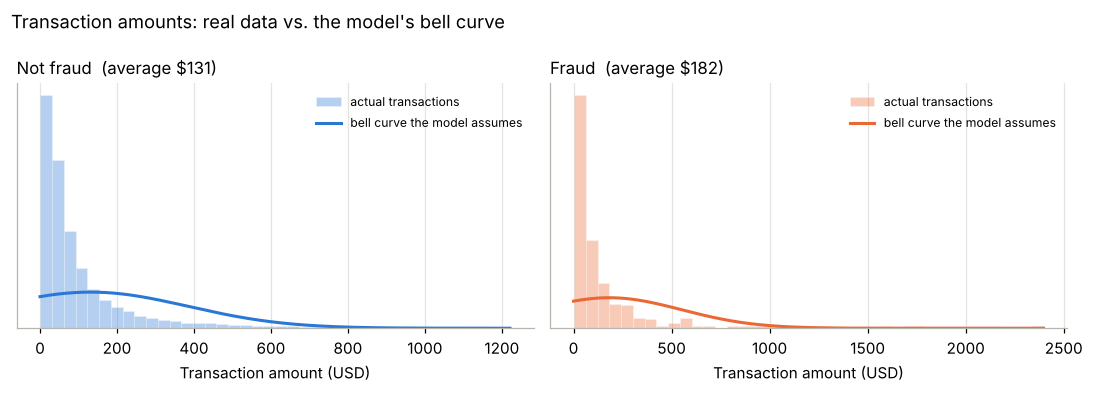

In [20]:
feature = "amount_usd"
f_index = NUMERIC_COLUMNS.index(feature)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, class_label, name, color in [(axes[0], 0, "Not fraud", NOT_FRAUD_COLOR),
                                     (axes[1], 1, "Fraud", FRAUD_COLOR)]:
    values = [numeric_train[i][f_index] for i in range(len(labels_train)) if labels_train[i] == class_label]
    upper = sorted(values)[int(0.99 * len(values))]          # trim the extreme 1% for readability
    shown = [v for v in values if v <= upper]
    mean_value, variance_value = model.numeric_feature_stats[class_label][f_index]

    ax.hist(shown, bins=40, density=True, color=color, alpha=0.35, edgecolor="white", linewidth=0.5,
            label="actual transactions")
    xs = [upper * k / 300 for k in range(301)]
    ax.plot(xs, [gaussian_probability(x, mean_value, variance_value) for x in xs],
            color=color, linewidth=2, label="bell curve the model assumes")
    ax.set_title(f"{name}  (average ${mean_value:,.0f})", loc="left", fontsize=11)
    ax.set_xlabel("Transaction amount (USD)")
    ax.set_yticks([])
    ax.legend(frameon=False, fontsize=8)

fig.suptitle("Transaction amounts: real data vs. the model's bell curve", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

The bell curve is only a rough fit. Real amounts are **skewed**: most purchases are small, with a long tail of large ones, and the bell curve even assigns probability to negative amounts. This is one of the classifier's weaknesses, revisited in Section 9.

## 7. How well does it work?

Now we reveal the hidden answers and compare them with the classifier's guesses on the 4,000 test transactions.

Every guess falls into one of four boxes (called the **confusion matrix**):

| | Classifier says **fraud** | Classifier says **normal** |
|---|---|---|
| **Actually fraud** | ✅ True positive (caught) | ❌ False negative (missed) |
| **Actually normal** | ❌ False positive (false alarm) | ✅ True negative |

From these we compute:

* **Accuracy**: what fraction of all guesses were right?
* **Precision**: of the transactions we *flagged*, how many were really fraud?
* **Recall**: of the transactions that *were* fraud, how many did we catch?

In [21]:
def calculate_confusion_matrix(true_labels, predicted_labels):
    tp = tn = fp = fn = 0
    for actual, predicted in zip(true_labels, predicted_labels):
        if actual == 1 and predicted == 1:
            tp += 1          # caught fraud
        elif actual == 0 and predicted == 0:
            tn += 1          # correctly left alone
        elif actual == 0 and predicted == 1:
            fp += 1          # false alarm
        else:
            fn += 1          # missed fraud
    return tp, tn, fp, fn


def evaluation_report(true_labels, predicted_labels):
    tp, tn, fp, fn = calculate_confusion_matrix(true_labels, predicted_labels)
    accuracy = (tp + tn) / len(true_labels)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    return {"caught (TP)": f"{tp:,}", "false alarms (FP)": f"{fp:,}",
            "missed (FN)": f"{fn:,}", "correct normal (TN)": f"{tn:,}",
            "accuracy": f"{accuracy:.1%}", "precision": f"{precision:.1%}",
            "recall": f"{recall:.1%}"}


train_predictions = model.predict(numeric_train, category_train)
test_predictions = model.predict(numeric_test, category_test)

pd.DataFrame({"training set": evaluation_report(labels_train, train_predictions),
              "test set": evaluation_report(labels_test, test_predictions)})

,training set,test set
caught (TP),85,27
false alarms (FP),378,67
missed (FN),186,41
correct normal (TN),"15,351","3,865"
accuracy,96.5%,97.3%
precision,18.4%,28.7%
recall,31.4%,39.7%


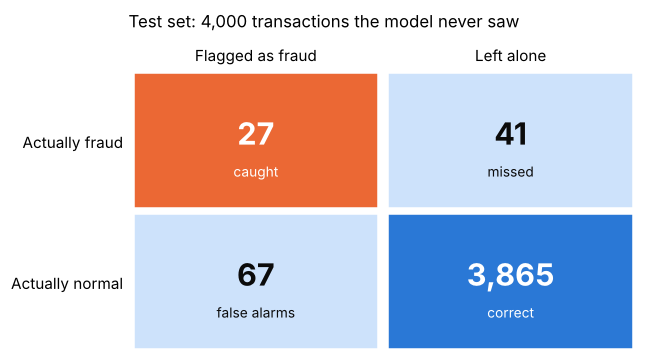

In [22]:
tp, tn, fp, fn = calculate_confusion_matrix(labels_test, test_predictions)
cells = [[tp, fn], [fp, tn]]
row_names = ["Actually fraud", "Actually normal"]
col_names = ["Flagged as fraud", "Left alone"]
fills = [["#eb6834", "#cde2fb"], ["#cde2fb", "#2a78d6"]]
notes = [["caught", "missed"], ["false alarms", "correct"]]

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.invert_yaxis(); ax.grid(False)
for r in range(2):
    for c in range(2):
        ax.add_patch(plt.Rectangle((c + 0.02, r + 0.02), 0.96, 0.96, color=fills[r][c], ec="white"))
        dark = fills[r][c] != "#cde2fb"
        ink = "white" if dark else "#0b0b0b"
        ax.text(c + 0.5, r + 0.45, f"{cells[r][c]:,}", ha="center", va="center", fontsize=20, color=ink, weight="bold")
        ax.text(c + 0.5, r + 0.72, notes[r][c], ha="center", va="center", fontsize=9, color=ink)
ax.set_xticks([0.5, 1.5], col_names); ax.set_yticks([0.5, 1.5], row_names)
ax.xaxis.tick_top(); ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Test set: 4,000 transactions the model never saw", loc="left", fontsize=11, pad=28)
fig.tight_layout()
plt.show()

### How to read these numbers

**Accuracy (about 97%) is misleading.** A "classifier" that *never* flags anything would be right 98.3% of the time, simply because fraud is rare, while catching zero fraud. That's why we look at precision and recall.

**Recall (about 40%):** the classifier caught roughly 4 in every 10 fraudulent transactions.

**Precision (about 29%):** of the transactions it flagged, fewer than a third were really fraud. Most alerts are false alarms.

**Why so many false alarms? Because fraud is rare.** This is known as the *base-rate effect*, and it also explains why medical screening tests for rare conditions produce many false positives. Only 1.7% of transactions are fraud. Even a small false-alarm rate, applied to 3,932 normal transactions, produces almost as many false alarms (67) as there are fraud cases to catch (68).

> **💬 In plain words:** when we're searching for something rare, even a good detector raises mostly false alarms, because there are so many more innocent cases than guilty ones.

*Why is the test set slightly better than the training set?* With only 68 fraud cases in the test set, a few lucky guesses move the numbers noticeably. Changing `random_seed` produces a different split and slightly different results.

## 8. Looking inside one decision

Because Naïve Bayes adds up one piece of evidence per detail, we can see exactly **which details pushed a transaction toward fraud** and by how much.

For each detail, we compare how typical its value is for fraud versus for normal:

$$
\text{push toward fraud} = \log P(\text{value} \mid \text{fraud}) - \log P(\text{value} \mid \text{not fraud})
$$

A positive number pushes toward fraud; a negative one pushes toward normal. The prior (fraud is rare) pushes strongly toward normal from the start, so the details have to overcome it.

In [23]:
def evidence_by_detail(model, numeric_row, category_row):
    # Return (detail name, push toward fraud) for every detail, plus the prior's push.
    pushes = []
    for f, value in enumerate(numeric_row):
        logs = []
        for c in (1, 0):
            mean_value, variance_value = model.numeric_feature_stats[c][f]
            logs.append(math.log(max(gaussian_probability(value, mean_value, variance_value), 1e-300)))
        pushes.append((NUMERIC_COLUMNS[f], logs[0] - logs[1]))
    for f, value in enumerate(category_row):
        logs = []
        for c in (1, 0):
            known = model.category_feature_likelihoods[f][c]
            p = known.get(value, model.category_feature_unseen_likelihood[f][c])
            logs.append(math.log(p))
        pushes.append((CATEGORY_COLUMNS[f], logs[0] - logs[1]))
    prior_push = math.log(model.prior_probability[1]) - math.log(model.prior_probability[0])
    return pushes, prior_push


def plot_evidence(model, index, title):
    pushes, prior_push = evidence_by_detail(model, numeric_test[index], category_test[index])
    pushes = sorted(pushes, key=lambda item: abs(item[1]), reverse=True)[:12][::-1]
    pushes = [("prior: fraud is rare", prior_push)] + pushes

    names = [n for n, _ in pushes]
    values = [v for _, v in pushes]
    colors = [FRAUD_COLOR if v > 0 else NOT_FRAUD_COLOR for v in values]

    fig, ax = plt.subplots(figsize=(8, 4.6))
    ax.barh(names, values, color=colors, height=0.6)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("← pushes toward NORMAL          pushes toward FRAUD →")
    ax.set_title(title, loc="left", fontsize=11)
    fig.tight_layout()
    plt.show()

### Finding one example of each outcome

We pick one transaction from each box of the confusion matrix to examine.

In [24]:
def first_index(actual, predicted):
    for i in range(len(labels_test)):
        if labels_test[i] == actual and test_predictions[i] == predicted:
            return i

examples = {"Caught fraud": first_index(1, 1),
            "Missed fraud": first_index(1, 0),
            "False alarm": first_index(0, 1),
            "Correctly left alone": first_index(0, 0)}

for name, i in examples.items():
    _, probs = model.predict_one_with_probability(numeric_test[i], category_test[i])
    print(f"{name:22s} test row {i:4d}: model's estimated chance of fraud = {probs[1]:.1%}")

Caught fraud           test row  182: model's estimated chance of fraud = 99.9%
Missed fraud           test row   95: model's estimated chance of fraud = 12.1%
False alarm            test row  163: model's estimated chance of fraud = 68.4%
Correctly left alone   test row    0: model's estimated chance of fraud = 0.0%


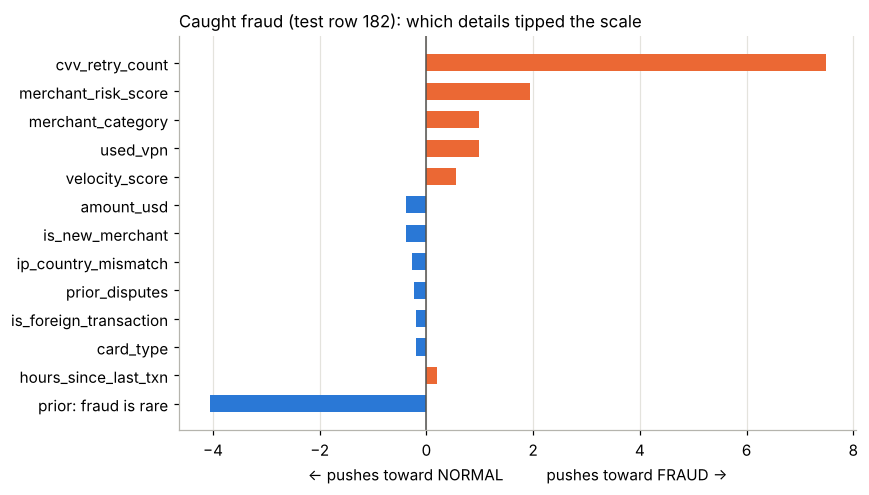

In [25]:
i = examples["Caught fraud"]
plot_evidence(model, i, f"Caught fraud (test row {i}): which details tipped the scale")

Each orange bar is a detail that looked more like fraud than normal. Together they outweighed the blue "fraud is rare" prior at the bottom.

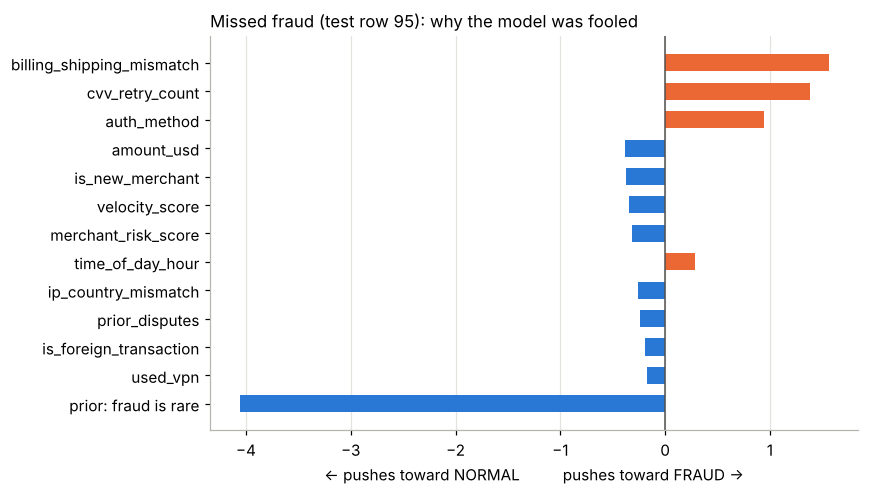

In [26]:
i = examples["Missed fraud"]
plot_evidence(model, i, f"Missed fraud (test row {i}): why the model was fooled")

A few details did look suspicious (the billing/shipping mismatch, the CVV retries). But most other details looked slightly normal, and those many small blue pushes, plus the strong "fraud is rare" prior, outweighed the warning signs. The model put the chance of fraud at about 12%: suspicious, but below the 50% cut-off.

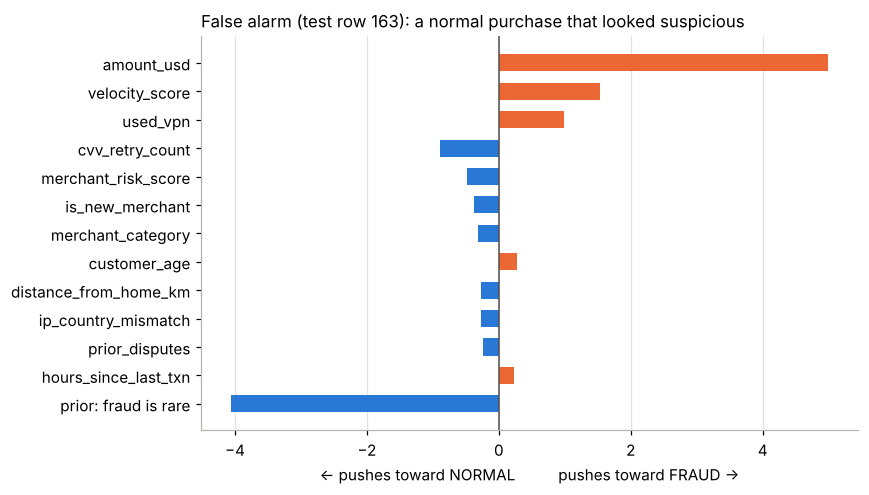

Amount of this purchase: $1,226.96


In [27]:
i = examples["False alarm"]
plot_evidence(model, i, f"False alarm (test row {i}): a normal purchase that looked suspicious")
print(f"Amount of this purchase: ${numeric_test[i][0]:,.2f}")

This was a legitimate \$1,227 purchase made over a VPN. The amount alone pushed hard toward fraud. That's partly the bell-curve problem from Section 6: the normal-purchase curve says amounts above about \$800 are almost impossible, even though real customers occasionally make them. A better model of amounts would push less hard here.

## 9. Limitations and next steps

**The naïve assumption double-counts evidence.** Details that travel together, like `is_foreign_transaction`, `distance_from_home_km` and `ip_country_mismatch`, are each counted as separate evidence, even though they largely tell the same story. This makes the classifier overconfident: notice how often its estimated percentages are near 0% or 100%.

**Some details don't fit a bell curve.**

* `amount_usd` and `account_balance_usd` are skewed (Section 6). Taking the logarithm of the amount first would give a much more bell-shaped curve.
* `time_of_day_hour` and `day_of_week` wrap around (hour 23 is next to hour 0), which a bell curve can't represent. Treating them as categories would be more natural.
* `cvv_retry_count` and `prior_disputes` are small whole-number counts that are mostly 0. They also fit better as categories.

**The threshold can be adjusted.** The classifier currently flags a transaction when fraud is more than 50% likely. A bank might prefer to flag anything above, say, 20%: more fraud caught (higher recall) at the cost of more false alarms (lower precision). Which trade-off is right depends on the cost of a missed fraud versus the cost of annoying a customer.

**Possible extensions:**

1. Re-run with the improvements above and compare recall and precision.
2. Compare against logistic regression, which does not assume independence - this is Section 10 below. (We skipped comparing against scikit-learn's own Naive Bayes classes specifically, since none of them handle a mix of number and category details the way this classifier does - see Section 10 for why.)

## 10. Checking our work against scikit-learn

Section 9 raised a concern: because Naive Bayes multiplies together the likelihood of each detail as if the details were independent, it can double-count details that travel together (like `is_foreign_transaction`, `distance_from_home_km`, and `ip_country_mismatch`), making the classifier overconfident.

To check that, we compare against **scikit-learn's logistic regression** rather than another Naive Bayes. Two reasons:

1. scikit-learn's own Naive Bayes classes (`GaussianNB`, `CategoricalNB`, ...) each handle only one kind of detail. There's no single built-in class that mixes number details and category details the way this notebook's classifier does, so comparing against one of them on its own wouldn't be a fair, full-model test.
2. Logistic regression does **not** assume the details are independent - it can learn how they relate to each other. If the independence assumption is really costing us something, logistic regression - trained on the exact same details and the exact same train/test split - should do noticeably better.

### Preparing the same data for scikit-learn

scikit-learn expects one table of features, with category details one-hot encoded (turned into a 0/1 column per possible value) and, for logistic regression, number details on a comparable scale. We build that table from the exact same `numeric_train`/`category_train`/`numeric_test`/`category_test` lists already split out above, so the comparison uses identical training and test rows.

In [ ]:
train_table = pd.DataFrame(numeric_train, columns=NUMERIC_COLUMNS)
for f, column_name in enumerate(CATEGORY_COLUMNS):
    train_table[column_name] = [row[f] for row in category_train]

test_table = pd.DataFrame(numeric_test, columns=NUMERIC_COLUMNS)
for f, column_name in enumerate(CATEGORY_COLUMNS):
    test_table[column_name] = [row[f] for row in category_test]

train_table.head(3)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Scale number details (so one detail with naturally larger numbers, like
# account_balance_usd, doesn't dominate just because of its units) and
# one-hot encode category details, then fit logistic regression on top.
preprocessing = ColumnTransformer([
    ("scale_numbers", StandardScaler(), NUMERIC_COLUMNS),
    ("encode_categories", OneHotEncoder(handle_unknown="ignore"), CATEGORY_COLUMNS),
])

sklearn_pipeline = Pipeline([
    ("prepare_features", preprocessing),
    ("logistic_regression", LogisticRegression(max_iter=1000)),
])

sklearn_pipeline.fit(train_table, labels_train)
sklearn_predictions = sklearn_pipeline.predict(test_table)
print("scikit-learn logistic regression trained.")

### Side-by-side results

In [ ]:
pd.DataFrame({
    "our Naive Bayes": evaluation_report(labels_test, test_predictions),
    "scikit-learn logistic regression": evaluation_report(labels_test, sklearn_predictions),
})

**The precision gap is the headline result.** Logistic regression reaches similar accuracy (about 99% vs. about 97%) while raising far fewer false alarms for roughly the same number of caught fraud cases - its precision (around 84%) is dramatically higher than our Naive Bayes model's (around 29%).

This matches the hypothesis from Section 9: treating correlated details as independent evidence makes Naive Bayes overconfident, pushing many borderline-normal transactions over the 50% threshold. Logistic regression, which can weigh correlated details together instead of multiplying each one in isolation, avoids much of that double-counting.

Naive Bayes does come out slightly ahead on **recall** - it casts a wider net, catching a few more real fraud cases, at the cost of far more false alarms. Which trade-off is "better" depends on what a bank cares about more: catching marginally more fraud, or bothering far fewer legitimate customers (the same trade-off discussed in Section 9).

### Do the two models agree on individual transactions?

In [ ]:
sklearn_probabilities = sklearn_pipeline.predict_proba(test_table)[:, 1]

for i in range(5):
    _, our_probabilities = model.predict_one_with_probability(numeric_test[i], category_test[i])
    actual_text = "FRAUD" if labels_test[i] == 1 else "not fraud"
    print(f"row {i}: our P(fraud) = {our_probabilities[1]:.1%}   "
          f"sklearn P(fraud) = {sklearn_probabilities[i]:.1%}   actual: {actual_text}")

The two models were built in completely different ways - one by counting and multiplying, the other by fitting weights to minimize error - yet on these five clear-cut, normal transactions they give almost the same low probability of fraud. Their differences show up on the harder cases near the 50% cut-off, which is where the precision and recall gap above comes from.

---

## Summary

* **Training** is counting: priors, percentages for category details, and a mean and variance for number details.
* **Prediction** is Bayes' theorem: multiply the prior by each detail's likelihood (in practice, add logarithms), then compare the two classes.
* **Smoothing** prevents a single never-seen value from vetoing all the other evidence.
* **Results** must be judged with precision and recall, not accuracy, because fraud is rare: when what we're looking for is rare, most alarms are false.
* **Checking our work** (Section 10) against scikit-learn's logistic regression confirmed a real cost of the independence assumption: it reached similar accuracy with far fewer false alarms, at a slightly lower recall.